# Brazilian E-Commerce: Personal portfolio project Jacki Nguyen  


**A SQL case study using the Olist dataset**  

Online orders tell more than a sales story. They also show how customers pay, which products move, and whether deliveries live up to expectations. This notebook looks at those connections using SQL, with a few charts to make the results easier to understand.

The source is [Olist's Brazilian E-Commerce Public Dataset on Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): around 100,000 orders from 2016–2018, stored across related CSV tables. All monetary values are in **Brazilian reais (BRL)**.

The five questions are straightforward:

1. How did monthly item sales and order counts change?
2. Which payment methods handled the most value?
3. Which product categories led sales in 2018?
4. Where were deliveries most often late?
5. Did late deliveries go hand in hand with worse reviews?

## 1. Data Set Up

Original Kaggle ZIP as `archive.zip`.The downloaded archive stays untouched, we only read the tables we need.

Python to handle the import and the charts. **SQLite to handle the actual analysis.** 

In [17]:
from pathlib import Path
from zipfile import ZipFile
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8.6, 4.3),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 10,
})

archive_candidates = [
    Path("archive.zip"), Path("olist_archive.zip"),
    Path("../archive.zip"), Path("../olist_archive.zip"),
]
archive_path = next((path for path in archive_candidates if path.is_file()), None)
if archive_path is None:
    raise FileNotFoundError(
        "Download the Olist dataset ZIP from Kaggle, name it archive.zip, "
        "and place it beside this notebook."
    )
print(f"Dataset ready: {archive_path.name}")


Dataset ready: archive.zip


In [18]:
# Read seven source CSVs directly from the ZIP, keeping only relevant columns.
# The dictionary maps original Kaggle names to short, clear SQL column names.
table_config = {
    "orders": ("olist_orders_dataset.csv", {
        "order_id": "order_id", "customer_id": "customer_id",
        "order_status": "order_status",
        "order_purchase_timestamp": "purchase_ts",
        "order_delivered_customer_date": "delivered_ts",
        "order_estimated_delivery_date": "estimated_delivery_ts"}),
    "order_items": ("olist_order_items_dataset.csv", {
        "order_id": "order_id", "order_item_id": "order_item_id",
        "product_id": "product_id", "price": "price",
        "freight_value": "freight_value"}),
    "order_payments": ("olist_order_payments_dataset.csv", {
        "order_id": "order_id", "payment_sequential": "payment_sequential",
        "payment_type": "payment_type",
        "payment_installments": "payment_installments",
        "payment_value": "payment_value"}),
    "customers": ("olist_customers_dataset.csv", {
        "customer_id": "customer_id", "customer_unique_id": "customer_unique_id",
        "customer_state": "customer_state"}),
    "reviews": ("olist_order_reviews_dataset.csv", {
        "review_id": "review_id", "order_id": "order_id",
        "review_score": "review_score"}),
    "products": ("olist_products_dataset.csv", {
        "product_id": "product_id",
        "product_category_name": "category_name"}),
    "category_translation": ("product_category_name_translation.csv", {
        "product_category_name": "category_pt",
        "product_category_name_english": "category_en"}),
}

conn = sqlite3.connect(":memory:")
counts = []
with ZipFile(archive_path) as archive:
    for table, (filename, columns) in table_config.items():
        data = pd.read_csv(archive.open(filename), usecols=list(columns))
        data = data.rename(columns=columns)
        data.to_sql(table, conn, if_exists="replace", index=False, chunksize=5000)
        counts.append((table, len(data)))

conn.executescript("""
CREATE INDEX idx_items_order ON order_items(order_id);
CREATE INDEX idx_payments_order ON order_payments(order_id);
CREATE INDEX idx_reviews_order ON reviews(order_id);
""")
display(pd.DataFrame(counts, columns=["Table", "Rows loaded"]))


,Table,Rows loaded
0,orders,99441
1,order_items,112650
2,order_payments,103886
3,customers,99441
4,reviews,99224
5,products,32951
6,category_translation,71


### A quick check before the analysis

One order can include several products and several payment records. If we join those tables directly, we could accidentally count the same sale more than once.

So I'll first build a small SQL view with **one row per delivered order**. Then I'll compare its item-sales total with a separate calculation straight from the item table. If they match, aggregation hasn't inflated sales.

In [19]:
# A reusable order-level view. Product prices exclude freight.
conn.executescript("""
-- Olist Brazilian e-commerce: SQL portfolio
-- BRL = Brazilian reais. Dates and status come from the original Kaggle CSVs.

-- One order can contain several items. Aggregates prices to the
-- order level first, so subsequent order counts are never inflated by joins.
CREATE TEMP VIEW IF NOT EXISTS delivered_order_sales AS
SELECT o.order_id, o.customer_id, o.purchase_ts,
       o.delivered_ts, o.estimated_delivery_ts,
       SUM(i.price) AS item_sales_brl
FROM orders AS o
JOIN order_items AS i ON i.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY o.order_id, o.customer_id, o.purchase_ts,
         o.delivered_ts, o.estimated_delivery_ts;


""")

check = pd.read_sql_query("""
SELECT (SELECT ROUND(SUM(i.price), 2)
        FROM order_items i JOIN orders o ON o.order_id = i.order_id
        WHERE o.order_status = 'delivered'
          AND o.purchase_ts >= '2017-01-01'
          AND o.purchase_ts < '2018-09-01') AS raw_item_sales_brl,
       (SELECT ROUND(SUM(item_sales_brl), 2)
        FROM delivered_order_sales
        WHERE purchase_ts >= '2017-01-01'
          AND purchase_ts < '2018-09-01') AS order_view_sales_brl
""", conn)
assert abs(check.iloc[0, 0] - check.iloc[0, 1]) < 0.01
display(check)
print("Check passed: both totals match.")


,raw_item_sales_brl,order_view_sales_brl
0,13181027.13,13181027.13


Check passed: both totals match.


## 2. Sales performance: growth from more orders

First, a basic `GROUP BY` and a few aggregations show monthly order counts, item sales and average item-sales value per delivered order. I use the purchase month, and restrict the analysis to January 2017–August 2018 because the very early and late months have patchy coverage.

In [20]:
sql_1 = """
SELECT SUBSTR(purchase_ts, 1, 7) AS purchase_month,
       COUNT(*) AS delivered_orders,
       ROUND(SUM(item_sales_brl), 2) AS item_sales_brl,
       ROUND(AVG(item_sales_brl), 2) AS avg_order_value_brl
FROM delivered_order_sales
WHERE purchase_ts >= '2017-01-01' AND purchase_ts < '2018-09-01'
GROUP BY SUBSTR(purchase_ts, 1, 7)
ORDER BY purchase_month;
"""
monthly = pd.read_sql_query(sql_1, conn)
display(monthly)


,purchase_month,delivered_orders,item_sales_brl,avg_order_value_brl
0,2017-01,750,111798.36,149.06
1,2017-02,1653,234223.40,141.70
2,2017-03,2546,359198.85,141.08
3,2017-04,2303,340669.68,147.92
4,2017-05,3546,489338.25,138.00
5,2017-06,3135,421923.37,134.58
6,2017-07,3872,481604.52,124.38
7,2017-08,4193,554699.70,132.29
8,2017-09,4150,607399.67,146.36
9,2017-10,4478,648247.65,144.76


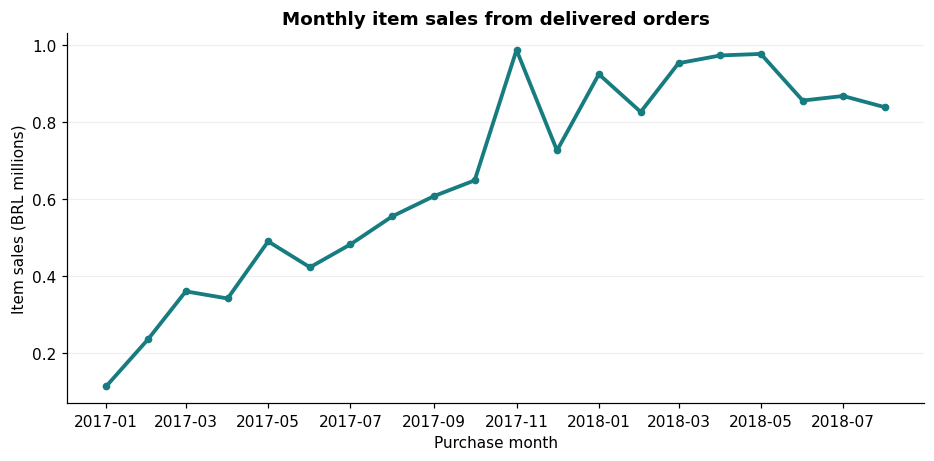

,year,delivered_orders,item_sales_brl,avg_order_value_brl
0,2017,21998,2993456.13,136.08
1,2018,52783,7218125.12,136.75


In [21]:
fig, ax = plt.subplots()
ax.plot(pd.to_datetime(monthly["purchase_month"]),
        monthly["item_sales_brl"] / 1_000_000,
        color="#167C80", linewidth=2.5, marker="o", markersize=4)
ax.set(title="Monthly item sales from delivered orders",
       ylabel="Item sales (BRL millions)", xlabel="Purchase month")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)

comparable = monthly[monthly["purchase_month"].str[5:7].astype(int) <= 8].copy()
comparable["year"] = comparable["purchase_month"].str[:4]
yo_y = comparable.groupby("year", as_index=True).agg(
    delivered_orders=("delivered_orders", "sum"),
    item_sales_brl=("item_sales_brl", "sum"))
yo_y["avg_order_value_brl"] = yo_y["item_sales_brl"] / yo_y["delivered_orders"]
display(yo_y.reset_index().round(2))


**What stands out:** Between January and August, item sales rose about **141%** from 2017 to 2018. Delivered-order volume increased by roughly **140%**, while average item-sales value per order barely moved (**+0.5%**). In other words, this growth was overwhelmingly about more orders, not customers spending much more per order.

## 3. Payment mix: credit cards dominate

This query joins the payments table to orders and uses a common table expression (CTE) to calculate each method's share of recorded payment value. It also counts distinct orders using each method.

The distinction matters: one order can have several payment records or methods. **Payment-value shares add up to 100%, but order counts across methods don't necessarily do so.**

In [22]:
sql_2 = """
-- Payment values include freight; orders can use multiple payment methods.
-- Therefore orders_using_method counts are not mutually exclusive.
WITH payment_mix AS (
    SELECT p.payment_type,
           COUNT(*) AS payment_rows,
           COUNT(DISTINCT p.order_id) AS orders_using_method,
           SUM(p.payment_value) AS payment_value_brl
    FROM order_payments AS p
    JOIN orders AS o ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered'
      AND o.purchase_ts >= '2017-01-01' AND o.purchase_ts < '2018-09-01'
    GROUP BY p.payment_type
)
SELECT payment_type, payment_rows, orders_using_method,
       ROUND(payment_value_brl, 2) AS payment_value_brl,
       ROUND(100.0 * payment_value_brl /
             (SELECT SUM(payment_value_brl) FROM payment_mix), 1)
             AS share_of_payment_value_pct
FROM payment_mix
ORDER BY payment_value_brl DESC;
"""
payments = pd.read_sql_query(sql_2, conn)
display(payments)


,payment_type,payment_rows,orders_using_method,payment_value_brl,share_of_payment_value_pct
0,credit_card,74376,74095,12063100.59,78.5
1,boleto,19140,19140,2762300.80,18.0
2,voucher,5473,3670,342294.66,2.2
3,debit_card,1484,1483,208179.39,1.4


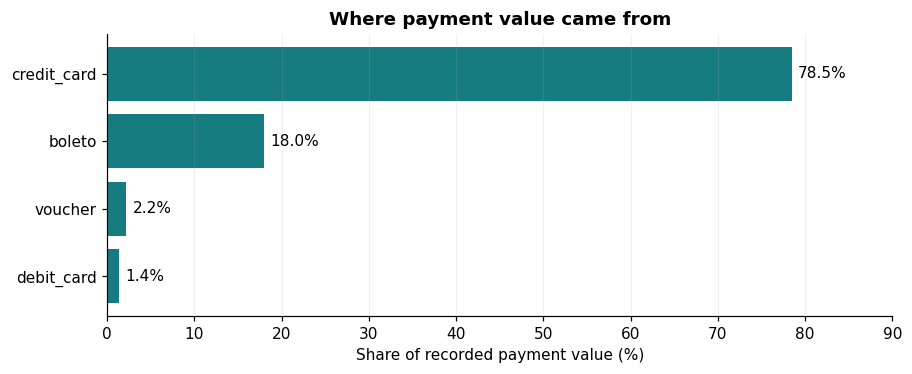

In [23]:
plot_data = payments.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.4, 3.5))
bars = ax.barh(plot_data["payment_type"], plot_data["share_of_payment_value_pct"],
               color="#167C80")
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set(xlabel="Share of recorded payment value (%)",
       title="Where payment value came from", xlim=(0, 90))
ax.grid(axis="x", alpha=0.18)
fig.tight_layout()
display(fig)
plt.close(fig)


**What stands out:** Credit cards accounted for **78.5%** of payment value, followed by *boleto* (a common Brazilian payment slip method) at **18.0%**. Payment values include amounts such as freight, so they shouldn't be confused with the item-price sales in the previous section.

## 4. Product categories: where sales were concentrated

For category sales, the correct starting point is the **order-item table**, not the order-level view. Each item belongs to a product, and each product has a category. Two `LEFT JOIN`s preserve products even if their category mapping is missing.

Here I focus on January–August 2018, ranking categories by item sales rather than units or order counts.

In [24]:
sql_3 = """
-- Use item rows for category sales; this is NOT payment revenue.
SELECT COALESCE(t.category_en, p.category_name, 'Unmapped') AS category,
       COUNT(*) AS items_sold,
       COUNT(DISTINCT i.order_id) AS orders_containing_category,
       ROUND(SUM(i.price), 2) AS item_sales_brl
FROM order_items AS i
JOIN delivered_order_sales AS d ON d.order_id = i.order_id
LEFT JOIN products AS p ON p.product_id = i.product_id
LEFT JOIN category_translation AS t ON t.category_pt = p.category_name
WHERE d.purchase_ts >= '2018-01-01' AND d.purchase_ts < '2018-09-01'
GROUP BY COALESCE(t.category_en, p.category_name, 'Unmapped')
ORDER BY item_sales_brl DESC
LIMIT 10;
"""
categories = pd.read_sql_query(sql_3, conn)
display(categories)


,category,items_sold,orders_containing_category,item_sales_brl
0,health_beauty,5841,5305,755724.50
1,watches_gifts,3628,3418,687855.20
2,bed_bath_table,5810,4844,532358.85
3,sports_leisure,4436,3973,517166.26
4,computers_accessories,4622,3972,496269.30
5,housewares,3969,3351,391823.46
6,furniture_decor,4051,3147,381649.57
7,auto,2580,2419,343288.30
8,baby,1731,1627,250615.79
9,cool_stuff,1447,1391,227743.70


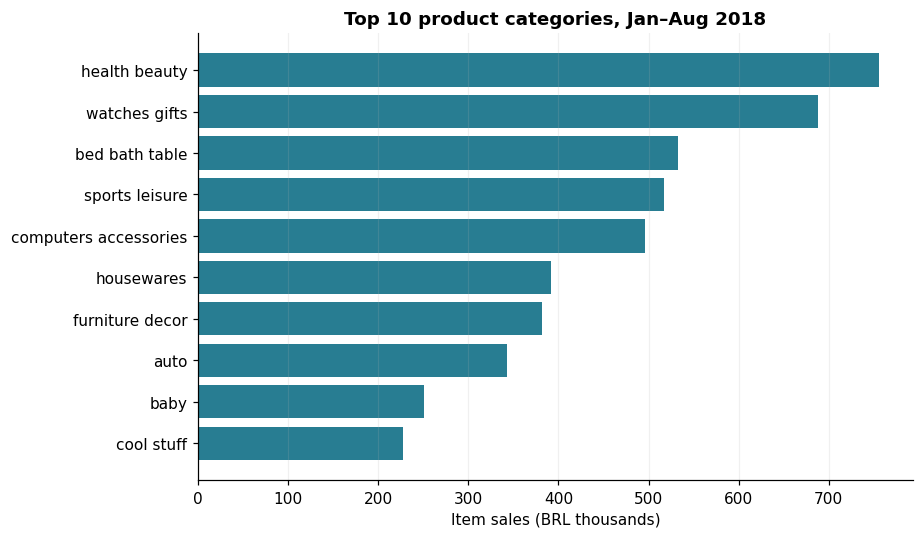

In [25]:
plot_data = categories.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(plot_data["category"].str.replace("_", " ", regex=False),
        plot_data["item_sales_brl"] / 1000,
        color="#287D92")
ax.set(xlabel="Item sales (BRL thousands)",
       title="Top 10 product categories, Jan–Aug 2018")
ax.grid(axis="x", alpha=0.18)
fig.tight_layout()
display(fig)
plt.close(fig)


**What stands out:** Health and beauty led the ranking with about **BRL 756k** in item sales, followed by watches and gifts at around **BRL 688k**. These are sales figures, not profits—the dataset doesn't contain product costs or margins.

## 5. Delivery reliability: rate versus scale

Let's switch to operations. An order counts as late when its actual delivery **date** comes after the estimated delivery **date**. Comparing dates rather than timestamps avoids flagging a parcel as late just because it arrived later on the promised day.

I only include states with at least 500 delivered orders to keep the rate comparison somewhat meaningful.

In [26]:
sql_4 = """
-- Compare delivery DATE to estimated DATE: estimates are stored at midnight.
SELECT c.customer_state,
       COUNT(*) AS delivered_orders,
       SUM(CASE WHEN DATE(d.delivered_ts) > DATE(d.estimated_delivery_ts)
                THEN 1 ELSE 0 END) AS late_orders,
       ROUND(100.0 * AVG(CASE WHEN DATE(d.delivered_ts) > DATE(d.estimated_delivery_ts)
                              THEN 1.0 ELSE 0.0 END), 1) AS late_rate_pct,
       ROUND(AVG(JULIANDAY(d.delivered_ts) - JULIANDAY(d.purchase_ts)), 1)
           AS avg_delivery_days
FROM delivered_order_sales AS d
JOIN customers AS c ON c.customer_id = d.customer_id
WHERE d.purchase_ts >= '2017-01-01' AND d.purchase_ts < '2018-09-01'
  AND d.delivered_ts IS NOT NULL AND d.estimated_delivery_ts IS NOT NULL
GROUP BY c.customer_state
HAVING COUNT(*) >= 500
ORDER BY late_rate_pct DESC, delivered_orders DESC
LIMIT 10;
"""
states = pd.read_sql_query(sql_4, conn)
display(states)


,customer_state,delivered_orders,late_orders,late_rate_pct,avg_delivery_days
0,MA,713,125,17.5,21.5
1,CE,1273,176,13.8,21.2
2,BA,3253,396,12.2,19.3
3,RJ,12310,1495,12.1,15.3
4,PA,942,106,11.3,23.8
5,ES,1992,214,10.7,15.8
6,PB,516,54,10.5,20.4
7,MS,701,68,9.7,15.6
8,PE,1587,153,9.6,18.4
9,SC,3537,291,8.2,14.9


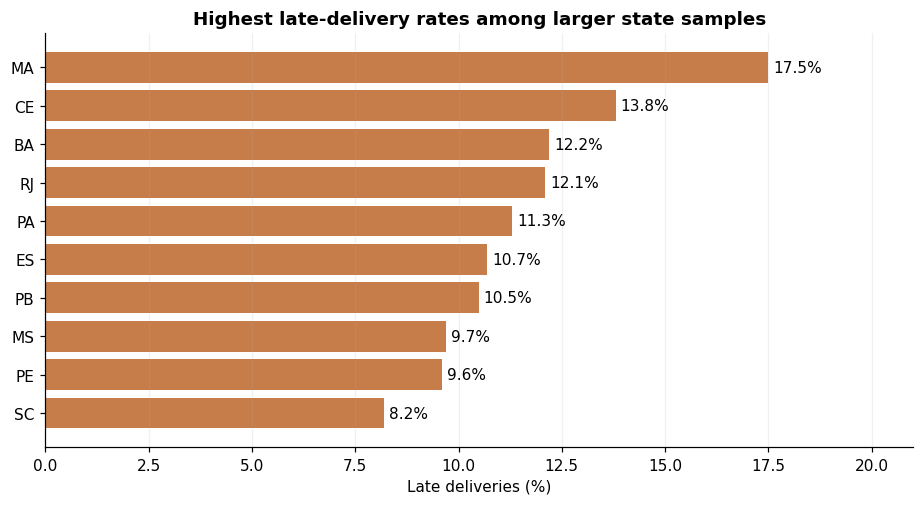

In [27]:
plot_data = states.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.7))
bars = ax.barh(plot_data["customer_state"], plot_data["late_rate_pct"],
               color="#C77D49")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(xlabel="Late deliveries (%)",
       title="Highest late-delivery rates among larger state samples",
       xlim=(0, 21))
ax.grid(axis="x", alpha=0.18)
fig.tight_layout()
display(fig)
plt.close(fig)


**What stands out:** Maranhão (MA) had the highest rate in this comparison (**17.5%**), but Rio de Janeiro (RJ) had many more delayed orders (**1,495**, despite a lower rate of **12.1%**). If a business were deciding where to focus, it would need to consider both the percentage and the actual number of affected customers.

## 6. Customer reviews: late orders receive poorer ratings

Finally, I connect delivery performance with reviews. Some orders have more than one review record, so the CTE first averages reviews at the **order level** before joining them to deliveries. That keeps each order from carrying extra weight.

In [28]:
sql_5 = """
-- Some orders have multiple reviews; aggregate reviews to one row per order.
WITH order_reviews AS (
    SELECT order_id, AVG(review_score) AS review_score
    FROM reviews
    GROUP BY order_id
)
SELECT CASE WHEN DATE(d.delivered_ts) > DATE(d.estimated_delivery_ts)
            THEN 'Late' ELSE 'On time or early' END AS delivery_group,
       COUNT(*) AS reviewed_orders,
       ROUND(AVG(r.review_score), 2) AS avg_review_score_out_of_5,
       ROUND(100.0 * AVG(CASE WHEN r.review_score <= 2
                              THEN 1.0 ELSE 0.0 END), 1)
           AS low_review_share_pct
FROM delivered_order_sales AS d
JOIN order_reviews AS r ON r.order_id = d.order_id
WHERE d.purchase_ts >= '2017-01-01' AND d.purchase_ts < '2018-09-01'
  AND d.delivered_ts IS NOT NULL AND d.estimated_delivery_ts IS NOT NULL
GROUP BY CASE WHEN DATE(d.delivered_ts) > DATE(d.estimated_delivery_ts)
              THEN 'Late' ELSE 'On time or early' END
ORDER BY delivery_group;
"""
reviews = pd.read_sql_query(sql_5, conn)
display(reviews)


,delivery_group,reviewed_orders,avg_review_score_out_of_5,low_review_share_pct
0,Late,6378,2.27,62.4
1,On time or early,89182,4.29,9.2


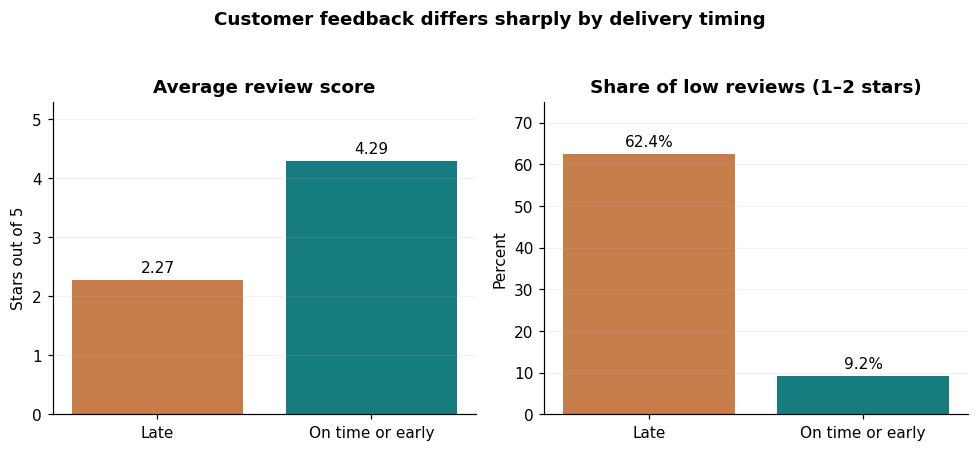

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.9))
labels = reviews["delivery_group"]
colors = ["#C77D49" if label == "Late" else "#167C80" for label in labels]

bars1 = axes[0].bar(labels, reviews["avg_review_score_out_of_5"], color=colors)
axes[0].bar_label(bars1, fmt="%.2f", padding=3)
axes[0].set(title="Average review score", ylabel="Stars out of 5", ylim=(0, 5.3))

bars2 = axes[1].bar(labels, reviews["low_review_share_pct"], color=colors)
axes[1].bar_label(bars2, fmt="%.1f%%", padding=3)
axes[1].set(title="Share of low reviews (1–2 stars)", ylabel="Percent", ylim=(0, 75))
for ax in axes:
    ax.grid(axis="y", alpha=0.16)
fig.suptitle("Customer feedback differs sharply by delivery timing",
             fontweight="bold", y=1.04)
fig.tight_layout()
display(fig)
plt.close(fig)


**What stands out:** Orders delivered late averaged **2.27 stars**, compared with **4.29 stars** for on-time or early deliveries. Low ratings (1–2 stars) appeared in **62.4%** of late orders with reviews, compared with **9.2%** for the on-time group.

That's a strong descriptive relationship, but it doesn't prove late delivery caused a bad review. Product quality, expectations and other factors could influence both.

## 7. What I'd take away

Three practical observations sum up the analysis:

- **Sales growth was volume-led.** More completed orders, rather than higher order values, explain almost all of the January–August year-over-year increase.
- **Payment preferences were concentrated.** Credit cards handled most recorded payment value, though *boleto* remained an important alternative.
- **Delivery is part of the customer experience.** Delays were associated with markedly weaker reviews. The state comparison also shows why it's useful to look at both late-delivery rates and the number of people affected.

### A few limits worth keeping in mind

This is historical data from 2016–2018, not a snapshot of the market today. Most queries focus on delivered orders purchased between January 2017 and August 2018. Excluding cancelled or undelivered orders means these results aren't a measure of every attempted purchase. Item sales exclude freight, payment values may include it, and the dataset doesn't support profit or causal claims. Review comparisons use orders with available review data only.

### SQL skills used

`SELECT` · `WHERE` · `JOIN` / `LEFT JOIN` · `GROUP BY` · `HAVING` · `ORDER BY` · `COUNT(DISTINCT)` · `CASE WHEN` · `SUM` / `AVG` · CTEs · views · date functions · aggregation checks

**Data attribution:** [Olist / Kaggle — Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).  